In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/datasprint-2-road-damage-detection/score.py
/kaggle/input/competitions/datasprint-2-road-damage-detection/benchmark_speed.py
/kaggle/input/competitions/datasprint-2-road-damage-detection/inference.py
/kaggle/input/competitions/datasprint-2-road-damage-detection/check_submission.py
/kaggle/input/competitions/datasprint-2-road-damage-detection/test_image_ids.csv
/kaggle/input/competitions/datasprint-2-road-damage-detection/train_baseline.py
/kaggle/input/competitions/datasprint-2-road-damage-detection/val_labels.csv
/kaggle/input/competitions/datasprint-2-road-damage-detection/README.md
/kaggle/input/competitions/datasprint-2-road-damage-detection/val_image_ids.csv
/kaggle/input/competitions/datasprint-2-road-damage-detection/requirements.txt
/kaggle/input/competitions/datasprint-2-road-damage-detection/train_labels.csv
/kaggle/input/competitions/datasprint-2-road-damage-detection/make_kaggle_submission.py
/kaggle/input/competitions/datasprint-2-road-damage-det

In [2]:
import os, random, glob, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm
import cv2

In [3]:
def find_kit():
    for root, dirs, fs in os.walk("/kaggle/input"):
        if "train_labels.csv" in fs:
            return Path(root)
    raise FileNotFoundError("train_labels.csv not found under /kaggle/input - add the competition data to the notebook")
KIT = find_kit()
print("KIT =", KIT)
OUT = Path("/kaggle/working")   # only /kaggle/working is writable

SEED = 42
random.seed(SEED); np.random.seed(SEED)
CLASS_NAMES = {0: "D00", 1: "D10", 2: "D20", 3: "D40"}
CLASS_COLORS = {0: "red", 1: "dodgerblue", 2: "lime", 3: "orange"}
plt.rcParams["figure.dpi"] = 110

KIT = /kaggle/input/competitions/datasprint-2-road-damage-detection


In [4]:
# loading files 
train_df = pd.read_csv(KIT / "train_labels.csv")
val_df   = pd.read_csv(KIT / "val_labels.csv")
val_ids  = pd.read_csv(KIT / "val_image_ids.csv")
test_ids = pd.read_csv(KIT / "test_image_ids.csv")

IMG_DIRS = {s: KIT / f"{s}_images" for s in ["train", "val", "test"]}
files = {s: sorted(os.listdir(d)) for s, d in IMG_DIRS.items()}

print("columns:", list(train_df.columns))
print(train_df.head())
for s in files:
    print(f"{s}: {len(files[s])} images")
print("train boxes:", len(train_df), "| val boxes:", len(val_df))
print("val_image_ids cols:", list(val_ids.columns), "| test_image_ids cols:", list(test_ids.columns))

columns: ['image_id', 'class_id', 'x_min', 'y_min', 'x_max', 'y_max']
     image_id  class_id  x_min  y_min  x_max  y_max
0  img_000005         0  301.0  405.0  414.0  522.0
1  img_000006         2  351.0  459.0  600.0  600.0
2  img_000006         3  377.0  540.0  423.0  600.0
3  img_000006         3  467.0  574.0  528.0  600.0
4  img_000013         1  239.0  493.0  383.0  517.0
train: 14691 images
val: 2150 images
test: 4200 images
train boxes: 17517 | val boxes: 2561
val_image_ids cols: ['image_id'] | test_image_ids cols: ['image_id']


In [6]:
def resolve(split, image_id):
    image_id = str(image_id)
    p = IMG_DIRS[split] / image_id
    if p.exists():
        return p
    for ext in (".jpg", ".jpeg", ".png"):
        q = IMG_DIRS[split] / (image_id + ext)
        if q.exists():
            return q
    return None
# Full list of image ids per split
def ids_from_files(split):
    return [Path(f).stem for f in files[split]]
train_all = ids_from_files("train"); val_all = ids_from_files("val"); test_all = ids_from_files("test")

def norm_id(x):  # make label ids comparable to folder stems
    return Path(str(x)).stem
train_df["img"] = train_df["image_id"].map(norm_id)
val_df["img"]   = val_df["image_id"].map(norm_id)

In [7]:
# label sanity check
def sanity(df, split, all_imgs):
    print(f"\n=== {split} ===")
    print("null cells:", int(df.isna().sum().sum()))
    print("class ids present:", sorted(df.class_id.unique()))
    w = df.x_max - df.x_min; h = df.y_max - df.y_min
    print("zero/negative width or height boxes:", int(((w <= 0) | (h <= 0)).sum()))
    print("negative coords:", int((df[["x_min","y_min"]] < 0).any(axis=1).sum()))
    missing = set(df.img) - set(all_imgs)
    print("label rows whose image file is missing:", len(missing))
    print("exact duplicate rows:", int(df.duplicated(["img","class_id","x_min","y_min","x_max","y_max"]).sum()))
sanity(train_df, "train", train_all)
sanity(val_df, "val", val_all)


=== train ===
null cells: 0
class ids present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
zero/negative width or height boxes: 0
negative coords: 0
label rows whose image file is missing: 0
exact duplicate rows: 0

=== val ===
null cells: 0
class ids present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
zero/negative width or height boxes: 0
negative coords: 0
label rows whose image file is missing: 0
exact duplicate rows: 0


In [8]:
# image size
def get_sizes(split):
    rows = []
    for f in tqdm(files[split], desc=f"sizes {split}"):
        with Image.open(IMG_DIRS[split] / f) as im:
            rows.append((Path(f).stem, im.width, im.height))
    return pd.DataFrame(rows, columns=["img", "W", "H"])

sizes = {s: get_sizes(s) for s in ["train", "val", "test"]}
for s, d in sizes.items():
    d["size"] = d.W.astype(str) + "x" + d.H.astype(str)
    print(f"\n{s}: top image sizes")
    print(d["size"].value_counts().head(8))

# Size groups roughly correspond to country/camera. Useful for per-group analysis later

sizes train:   0%|          | 0/14691 [00:00<?, ?it/s]

sizes val:   0%|          | 0/2150 [00:00<?, ?it/s]

sizes test:   0%|          | 0/4200 [00:00<?, ?it/s]


train: top image sizes
size
600x600      9123
720x720      5356
1024x1024      98
540x540        84
1080x1080      30
Name: count, dtype: int64

val: top image sizes
size
600x600      1304
720x720       800
1024x1024      22
540x540        19
1080x1080       5
Name: count, dtype: int64

test: top image sizes
size
600x600      2589
720x720      1550
1024x1024      27
540x540        21
1080x1080      13
Name: count, dtype: int64


          train  val  train_%  val_%
class_id                            
D00        4600  695     26.3   27.1
D10        3132  454     17.9   17.7
D20        5864  824     33.5   32.2
D40        3921  588     22.4   23.0


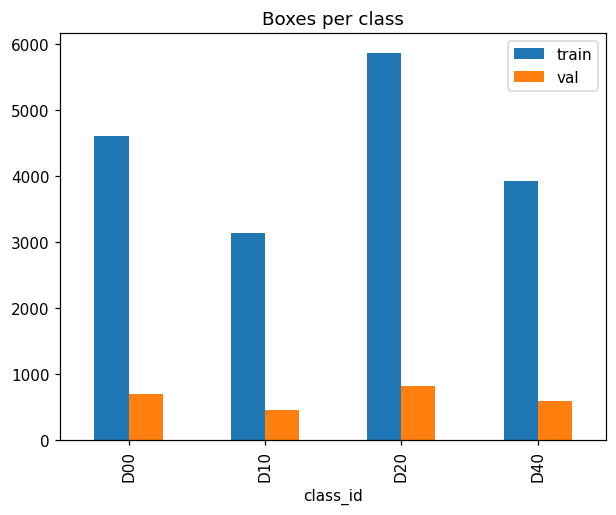


Train images containing each class:
 class_id
D00    3279
D10    1835
D20    4619
D40    2120
Name: img, dtype: int64


In [9]:
# class distribution
def class_counts(df):
    return df.class_id.map(CLASS_NAMES).value_counts().reindex(CLASS_NAMES.values()).fillna(0).astype(int)

cc = pd.DataFrame({"train": class_counts(train_df), "val": class_counts(val_df)})
cc["train_%"] = (100 * cc.train / cc.train.sum()).round(1)
cc["val_%"] = (100 * cc.val / cc.val.sum()).round(1)
print(cc)
cc[["train", "val"]].plot(kind="bar", title="Boxes per class")
plt.show()

# Images containing each class
img_has = train_df.groupby("class_id").img.nunique().rename(index=CLASS_NAMES)
print("\nTrain images containing each class:\n", img_has)

train: 8523/14691 images have damage, 6168 empty (42.0%)
val: 1254/2150 images have damage, 896 empty (41.7%)

Boxes per image (train):
count    14691.000000
mean         1.192363
std          1.495407
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         14.000000
dtype: float64


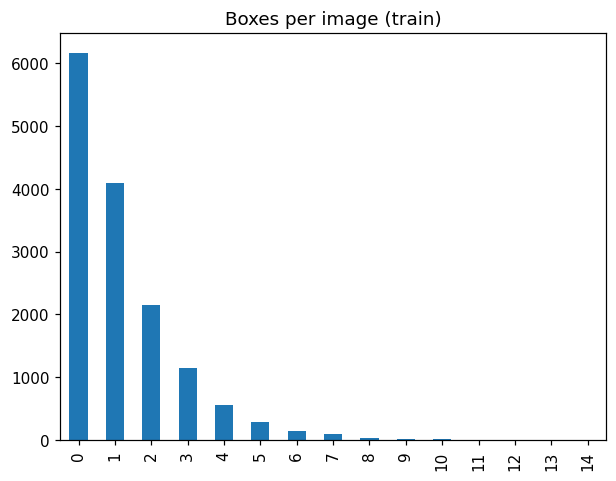

In [10]:
# checking for empty or damaged images
for name, df, all_imgs in [("train", train_df, train_all), ("val", val_df, val_all)]:
    n_dmg = df.img.nunique()
    n_all = len(all_imgs)
    print(f"{name}: {n_dmg}/{n_all} images have damage, {n_all-n_dmg} empty ({100*(n_all-n_dmg)/n_all:.1f}%)")

bpi = train_df.groupby("img").size().reindex(train_all).fillna(0).astype(int)
print("\nBoxes per image (train):")
print(bpi.describe())
bpi.value_counts().sort_index().head(20).plot(kind="bar", title="Boxes per image (train)")
plt.show()

cls                  D00       D10       D20       D40
rel_w    count  4600.000  3132.000  5864.000  3921.000
         mean      0.121     0.252     0.407     0.139
         std       0.081     0.146     0.243     0.115
         min       0.013     0.030     0.032     0.017
         25%       0.063     0.152     0.218     0.068
         50%       0.100     0.215     0.345     0.103
         75%       0.156     0.310     0.544     0.164
         max       0.967     0.990     0.999     0.997
rel_h    count  4600.000  3132.000  5864.000  3921.000
         mean      0.165     0.048     0.262     0.081
         std       0.094     0.025     0.138     0.062
         min       0.018     0.007     0.027     0.015
         25%       0.098     0.032     0.160     0.042
         50%       0.143     0.042     0.243     0.060
         75%       0.208     0.057     0.343     0.095
         max       0.695     0.397     0.993     0.476
rel_area count  4600.000  3132.000  5864.000  3921.000
         m

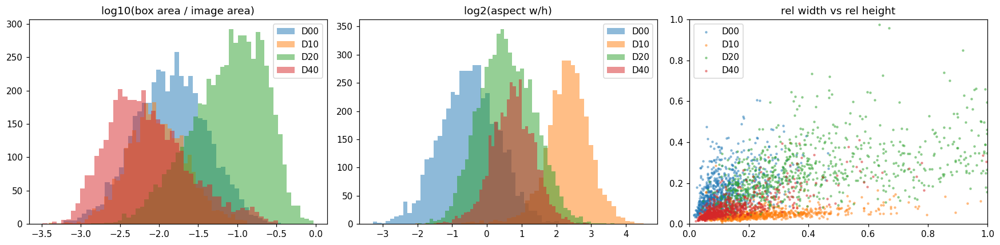

In [11]:
tr = train_df.merge(sizes["train"][["img","W","H"]], on="img", how="left")
tr["w"] = tr.x_max - tr.x_min
tr["h"] = tr.y_max - tr.y_min
tr["area"] = tr.w * tr.h
tr["rel_w"] = tr.w / tr.W
tr["rel_h"] = tr.h / tr.H
tr["rel_area"] = tr.area / (tr.W * tr.H)
tr["aspect"] = tr.w / tr.h.clip(lower=1)
tr["cls"] = tr.class_id.map(CLASS_NAMES)

print(tr.groupby("cls")[["rel_w", "rel_h", "rel_area", "aspect"]].describe().T.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for c, g in tr.groupby("cls"):
    ax[0].hist(np.log10(g.rel_area.clip(lower=1e-6)), bins=50, alpha=.5, label=c)
    ax[1].hist(np.log2(g.aspect.clip(lower=0.01)), bins=50, alpha=.5, label=c)
    ax[2].scatter(g.rel_w.sample(min(len(g), 800), random_state=0),
                  g.rel_h.sample(min(len(g), 800), random_state=0), s=4, alpha=.4, label=c)
ax[0].set_title("log10(box area / image area)"); ax[1].set_title("log2(aspect w/h)")
ax[2].set_title("rel width vs rel height"); ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1)
for a in ax: a.legend()
plt.tight_layout(); plt.show()

In [12]:
# Box size in pixels after resizing the LONG side of the image to imgsz
print("Share of boxes with min(side) < k px after resize (by imgsz):")
rows = []
for imgsz in [512, 640, 800, 1024, 1280]:
    scale = imgsz / tr[["W", "H"]].max(axis=1)
    short = (tr[["w", "h"]].min(axis=1) * scale)
    rows.append({"imgsz": imgsz, "<4px %": 100*(short < 4).mean(), "<8px %": 100*(short < 8).mean(),
                 "<16px %": 100*(short < 16).mean(), "median short side px": short.median()})
print(pd.DataFrame(rows).round(1).to_string(index=False))

Share of boxes with min(side) < k px after resize (by imgsz):
 imgsz  <4px %  <8px %  <16px %  median short side px
   512     0.0     0.1      6.6                  46.9
   640     0.0     0.0      2.2                  58.7
   800     0.0     0.0      0.6                  73.3
  1024     0.0     0.0      0.1                  93.9
  1280     0.0     0.0      0.0                 117.3


In [13]:
# per image size group analysis
tr["size"] = tr.W.astype(str) + "x" + tr.H.astype(str)
tbl = pd.crosstab(tr["size"], tr["cls"])
tbl["n_images_in_split"] = sizes["train"]["size"].value_counts().reindex(tbl.index)
print(tbl.sort_values("n_images_in_split", ascending=False).head(10))
# If groups differ a lot in class mix, consider stratifying checks by size group.

cls         D00   D10   D20   D40  n_images_in_split
size                                                
600x600    3490  3070  4342  1421               9123
720x720    1084    51  1398  2230               5356
1024x1024     6     0    12   156                 98
540x540      17    10    98    73                 84
1080x1080     3     1    14    41                 30


Random damaged train images


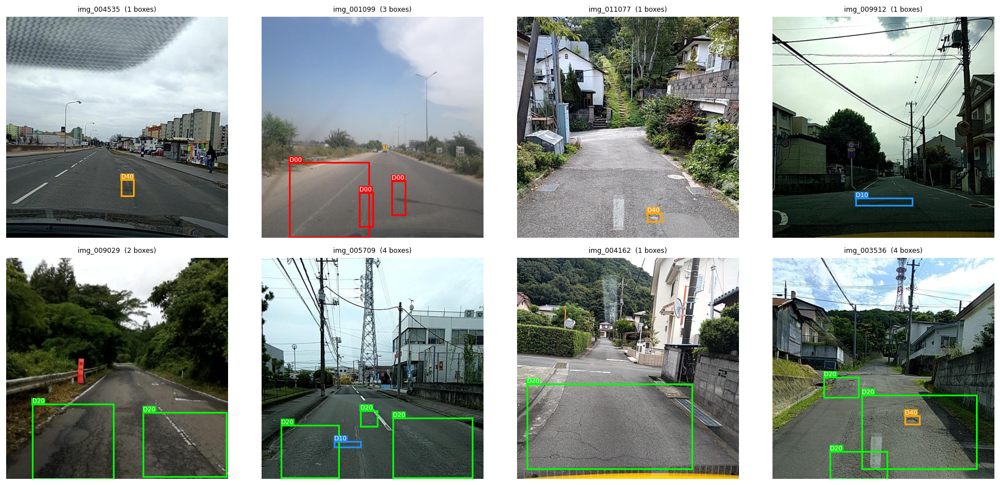

In [14]:
# visualizing samples with boxes
def draw(ax, split, img_id, df):
    p = resolve(split, img_id)
    im = Image.open(p).convert("RGB")
    ax.imshow(im); ax.axis("off")
    sub = df[df.img == norm_id(img_id)]
    for _, r in sub.iterrows():
        c = int(r.class_id)
        ax.add_patch(patches.Rectangle((r.x_min, r.y_min), r.x_max - r.x_min, r.y_max - r.y_min,
                                       fill=False, edgecolor=CLASS_COLORS[c], linewidth=2))
        ax.text(r.x_min, max(r.y_min - 3, 0), CLASS_NAMES[c], color="white", fontsize=7,
                bbox=dict(facecolor=CLASS_COLORS[c], alpha=.8, pad=1, edgecolor="none"))
    ax.set_title(f"{norm_id(img_id)}  ({len(sub)} boxes)", fontsize=8)

def show_grid(split, df, ids, n=8, cols=4):
    ids = random.sample(list(ids), min(n, len(ids)))
    rows = int(np.ceil(len(ids) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(4.2 * cols, 4 * rows))
    for a, i in zip(np.array(axs).ravel(), ids):
        draw(a, split, i, df)
    for a in np.array(axs).ravel()[len(ids):]: a.axis("off")
    plt.tight_layout(); plt.show()

print("Random damaged train images")
show_grid("train", train_df, train_df.img.unique(), n=8)

Class 0 D00


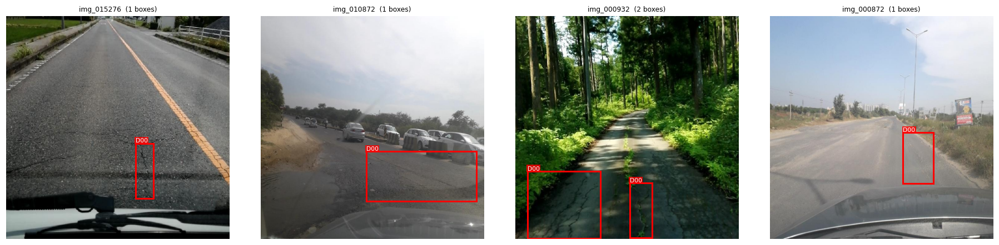

Class 1 D10


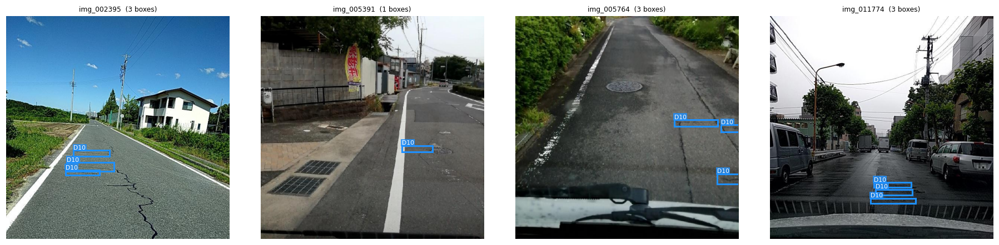

Class 2 D20


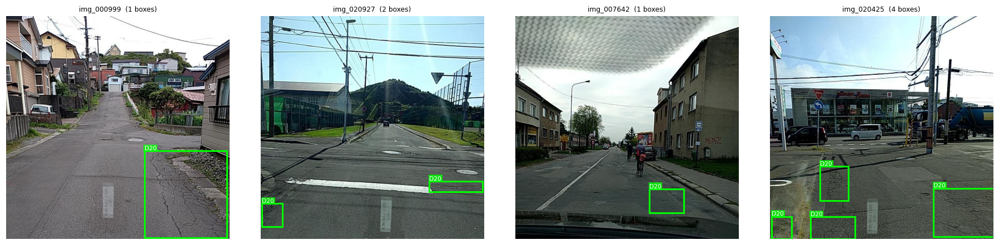

Class 3 D40


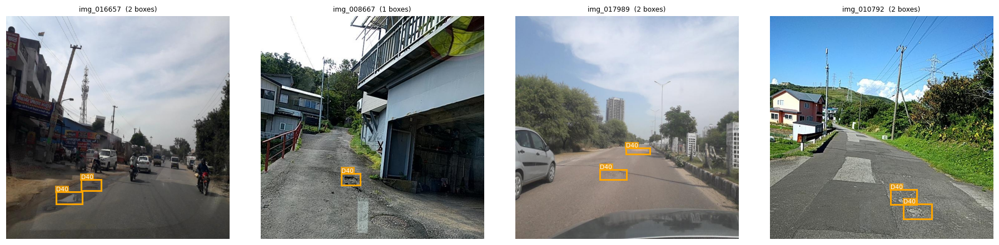

In [15]:
# visualizing each class sample images 
for c in range(4):
    print("Class", c, CLASS_NAMES[c])
    ids = train_df[train_df.class_id == c].img.unique()
    show_grid("train", train_df[train_df.class_id == c], ids, n=4)

Empty train images: 6168


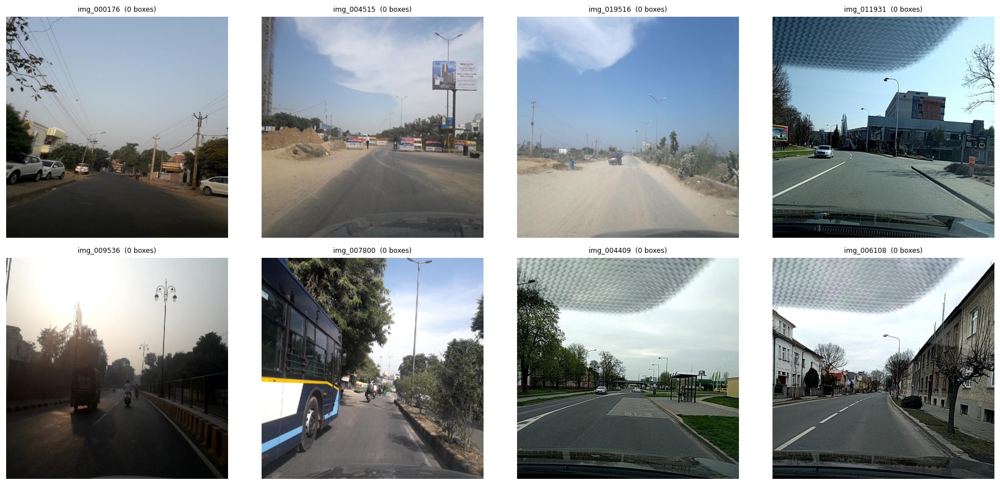

Most crowded images


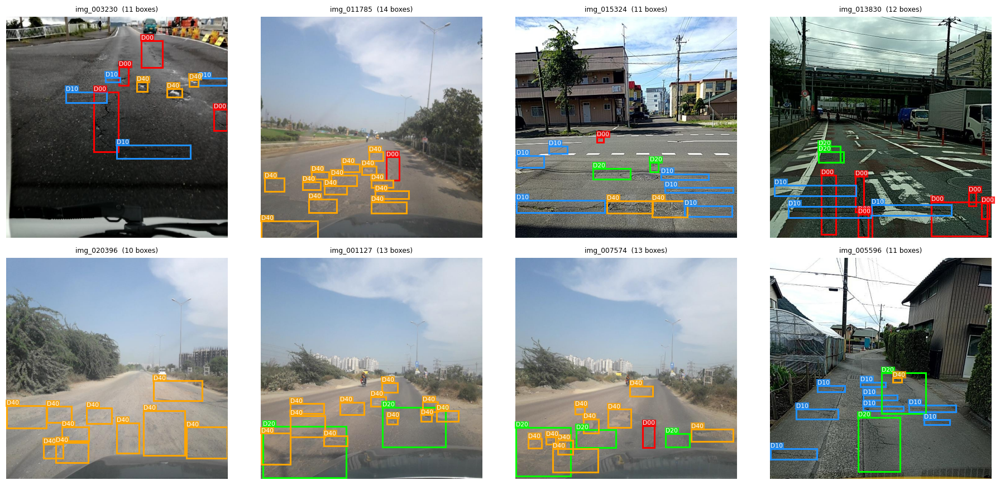

In [16]:
empty_ids = sorted(set(train_all) - set(train_df.img))
print("Empty train images:", len(empty_ids))
show_grid("train", train_df, empty_ids, n=8)

# %% 9d. Images with the most boxes / largest boxes ----------------------
print("Most crowded images")
show_grid("train", train_df, bpi.sort_values(ascending=False).head(8).index, n=8)

quality train:   0%|          | 0/1500 [00:00<?, ?it/s]

quality val:   0%|          | 0/1500 [00:00<?, ?it/s]

quality test:   0%|          | 0/1500 [00:00<?, ?it/s]


train
               mean     std    min     25%     50%      75%       max
brightness   118.60   20.62  42.10  107.76  119.43   131.33    169.59
contrast      67.61   14.77  23.36   56.83   70.30    78.80     98.28
blur_lapvar  910.60  926.03   8.88  255.29  770.89  1368.54  14142.60
noise          7.00    3.30   0.69    4.05    7.12     9.52     29.11

val
               mean     std    min     25%     50%      75%       max
brightness   119.61   20.36  54.75  108.53  120.14   131.65    175.14
contrast      67.39   15.19  21.19   56.05   70.31    79.00     99.43
blur_lapvar  892.57  873.76  14.07  268.96  754.19  1325.82  11414.56
noise          6.94    3.24   0.94    4.13    7.06     9.37     25.79

test
               mean     std    min     25%     50%      75%       max
brightness   112.47   29.20  20.52  101.82  117.40   130.09    167.25
contrast      64.09   18.30   9.35   52.43   68.25    77.87    100.03
blur_lapvar  839.12  912.57   1.84  189.48  580.64  1361.37  18362.35
no

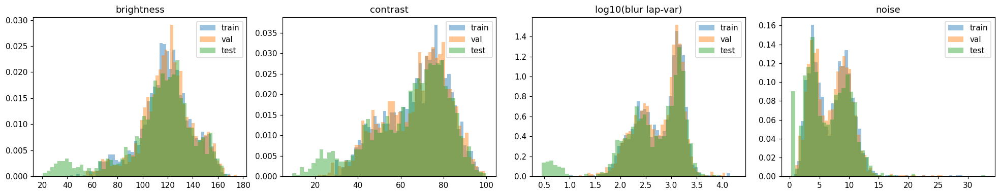

In [17]:
# Image quality stats: brightness, contrast, blur, noise
def quality(path):
    im = cv2.imread(str(path))
    if im is None:
        return None
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    g_small = cv2.resize(g, (640, int(640 * g.shape[0] / g.shape[1])))
    lap_var = cv2.Laplacian(g_small, cv2.CV_64F).var()                 # low = blurry
    brightness = g_small.mean()                                         # low = dark
    contrast = g_small.std()
    # noise estimate: std of (image - median blur)
    noise = (g_small.astype(np.float32) - cv2.medianBlur(g_small, 3).astype(np.float32)).std()
    return brightness, contrast, lap_var, noise

def quality_df(split, n=1500):
    fs = random.sample(files[split], min(n, len(files[split])))
    rows = []
    for f in tqdm(fs, desc=f"quality {split}"):
        q = quality(IMG_DIRS[split] / f)
        if q: rows.append((Path(f).stem, *q))
    return pd.DataFrame(rows, columns=["img", "brightness", "contrast", "blur_lapvar", "noise"])

qual = {s: quality_df(s) for s in ["train", "val", "test"]}
for s, d in qual.items():
    print(f"\n{s}"); print(d.describe().round(2).T[["mean", "std", "min", "25%", "50%", "75%", "max"]])

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for i, col in enumerate(["brightness", "contrast", "blur_lapvar", "noise"]):
    for s, d in qual.items():
        v = d[col] if col != "blur_lapvar" else np.log10(d[col] + 1)
        ax[i].hist(v, bins=50, alpha=.45, density=True, label=s)
    ax[i].set_title(col if col != "blur_lapvar" else "log10(blur lap-var)"); ax[i].legend()
plt.tight_layout(); plt.show()


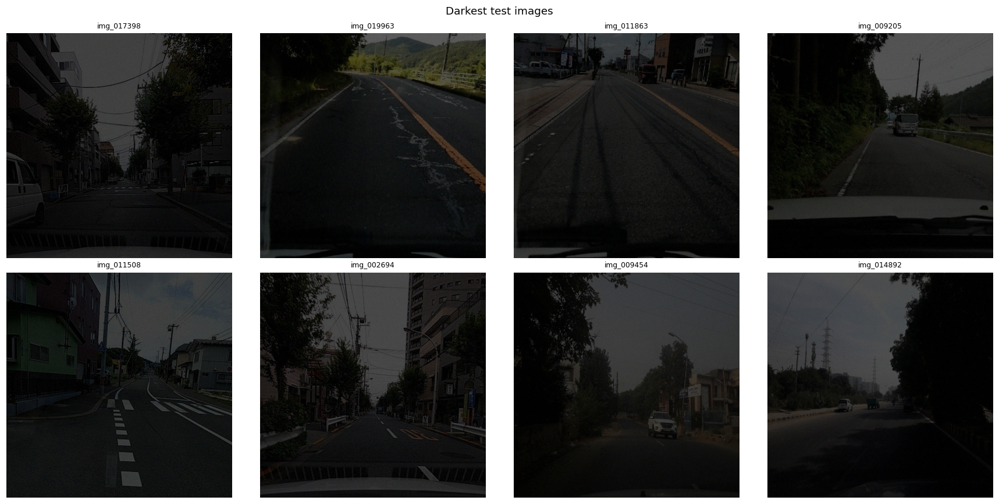

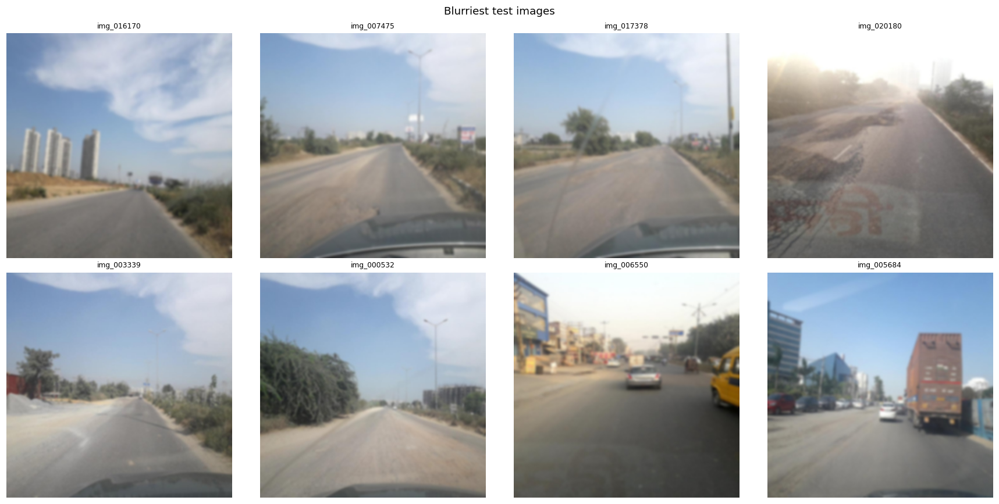

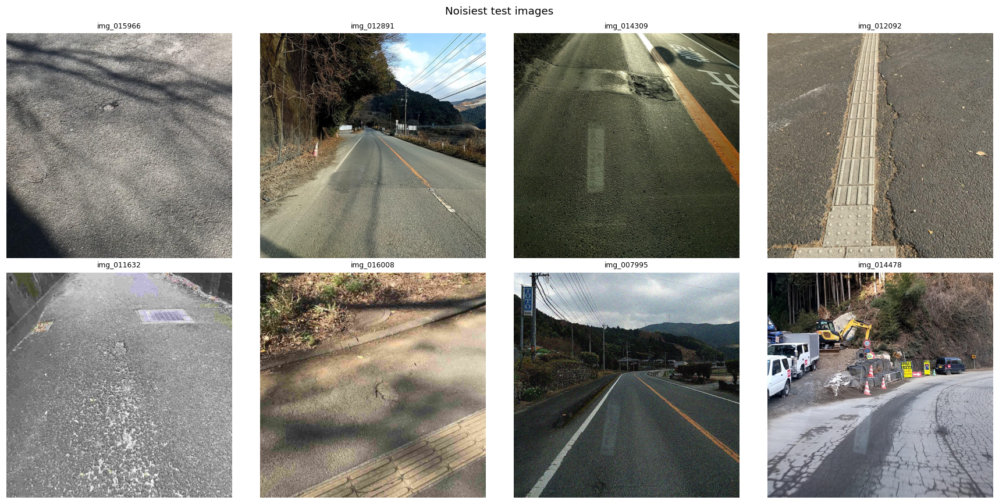

In [18]:
# Look at the worst-quality test images
q = qual["test"]
def show_files(split, names, title):
    fig, axs = plt.subplots(2, 4, figsize=(16, 8)); fig.suptitle(title)
    for a, n in zip(axs.ravel(), names):
        a.imshow(Image.open(resolve(split, n)).convert("RGB")); a.axis("off"); a.set_title(n, fontsize=8)
    plt.tight_layout(); plt.show()
show_files("test", q.nsmallest(8, "brightness").img, "Darkest test images")
show_files("test", q.nsmallest(8, "blur_lapvar").img, "Blurriest test images")
show_files("test", q.nlargest(8, "noise").img, "Noisiest test images")

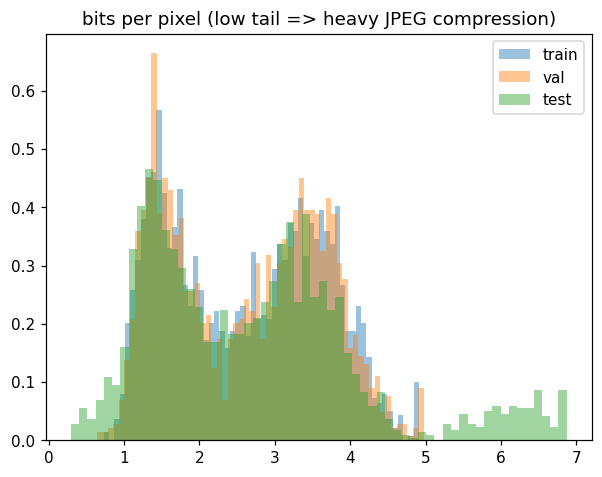

In [19]:
# File size / JPEG quality proxy
def bpp_df(split, n=2000):
    fs = random.sample(files[split], min(n, len(files[split])))
    rows = []
    for f in fs:
        p = IMG_DIRS[split] / f
        with Image.open(p) as im:
            rows.append((Path(f).stem, os.path.getsize(p) * 8 / (im.width * im.height)))
    return pd.DataFrame(rows, columns=["img", "bits_per_pixel"])
bpp = {s: bpp_df(s) for s in ["train", "val", "test"]}
for s, d in bpp.items():
    plt.hist(d.bits_per_pixel.clip(upper=d.bits_per_pixel.quantile(.995)), bins=60, alpha=.45, density=True, label=s)
plt.title("bits per pixel (low tail => heavy JPEG compression)"); plt.legend(); plt.show()

In [20]:
# Does image quality relate to damage presence?
qt = qual["train"].copy()
qt["has_damage"] = qt.img.isin(set(train_df.img))
print(qt.groupby("has_damage")[["brightness", "contrast", "blur_lapvar", "noise"]].mean().round(2))

            brightness  contrast  blur_lapvar  noise
has_damage                                          
False           123.40     70.04       815.25   6.66
True            115.02     65.80       981.75   7.25


In [21]:
def ahash(path, hs=8):
    im = Image.open(path).convert("L").resize((hs, hs), Image.BILINEAR)
    a = np.asarray(im, dtype=np.float32)
    return (a > a.mean()).flatten()

def hash_split(split, n=1500):
    fs = random.sample(files[split], min(n, len(files[split])))
    return {Path(f).stem: ahash(IMG_DIRS[split] / f) for f in tqdm(fs, desc=f"hash {split}")}

h_tr, h_va = hash_split("train"), hash_split("val")
tr_keys = list(h_tr); tr_mat = np.stack([h_tr[k] for k in tr_keys])
hits = 0
for k, v in h_va.items():
    d = (tr_mat != v).sum(1)
    if d.min() <= 2:
        hits += 1
print(f"val sample images with a near-identical train image (hamming<=2): {hits}/{len(h_va)}")

hash train:   0%|          | 0/1500 [00:00<?, ?it/s]

hash val:   0%|          | 0/1500 [00:00<?, ?it/s]

val sample images with a near-identical train image (hamming<=2): 750/1500


In [23]:
co = pd.crosstab(train_df.img, train_df.class_id.map(CLASS_NAMES)).clip(upper=1)
print((co.T @ co))

# %% 14. Hand-off: dump a summary JSON to carry into the Kaggle notebook -
summary = {
    "n_images": {s: len(files[s]) for s in files},
    "n_boxes": {"train": int(len(train_df)), "val": int(len(val_df))},
    "class_counts_train": {CLASS_NAMES[k]: int(v) for k, v in train_df.class_id.value_counts().items()},
    "empty_train_images": len(empty_ids),
    "top_sizes_train": sizes["train"]["size"].value_counts().head(5).to_dict(),
    "median_rel_area_by_class": tr.groupby("cls").rel_area.median().round(5).to_dict(),
}
(OUT / "eda_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

class_id   D00   D10   D20   D40
class_id                        
D00       3279   758   864   387
D10        758  1835   734   152
D20        864   734  4619   942
D40        387   152   942  2120
{
  "n_images": {
    "train": 14691,
    "val": 2150,
    "test": 4200
  },
  "n_boxes": {
    "train": 17517,
    "val": 2561
  },
  "class_counts_train": {
    "D20": 5864,
    "D00": 4600,
    "D40": 3921,
    "D10": 3132
  },
  "empty_train_images": 6168,
  "top_sizes_train": {
    "600x600": 9123,
    "720x720": 5356,
    "1024x1024": 98,
    "540x540": 84,
    "1080x1080": 30
  },
  "median_rel_area_by_class": {
    "D00": 0.0143,
    "D10": 0.00907,
    "D20": 0.08709,
    "D40": 0.00617
  }
}
